# Final Thesis Experiment — Joint AgriCLIP Prompt + SAM2 Encoder Adaptation

**Goal:** test whether difficult cross-domain failures come from the interaction between **AgriCLIP prompt quality** and the **SAM2 visual representation**.

This notebook independently evaluates **ReLeaf, WeedsGalore, and EWI1S**. For each target domain, the same small labelled training subset is used to:

1. fine-tune a copy of the **AgriCLIP DINO→concept aligner** using GT-derived patch labels;
2. train a lightweight **SAM2 encoder feature adapter** while keeping the dataset-specific decoder fixed;
3. evaluate four conditions on the untouched validation split: **Baseline, Encoder only, Prompt only, Joint adaptation**.

Primary outputs: **AgriCLIP Box IoU** and **SAM2 Mask IoU**, plus Dice, Precision, Recall, runtime, per-image gains and a paired statistical comparison.

> Validation labels are never used for training/adaptation.

In [1]:
# CELL 1 — Imports and environment
import os, sys, json, copy, random, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import Sam2Model, Sam2Processor
from torchvision import transforms

warnings.filterwarnings("ignore")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0


In [2]:
# CELL 2 — Reproducibility and experiment configuration
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = DEVICE
MODEL_NAME = "facebook/sam2.1-hiera-tiny"

# Main thesis experiment: small target-domain labelled subset
LABEL_BUDGET = 20
RUN_LABEL_BUDGET_ABLATION = False
LABEL_BUDGETS = [5, 10, 20, 50]

TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5

# AgriCLIP prompting adaptation
PATCH_POSITIVE_THRESHOLD = 0.10
ALIGNER_EPOCHS = 25
ALIGNER_LR = 1e-5
ALIGNER_WEIGHT_DECAY = 1e-4
ALIGNER_PATIENCE = 5
SIMILARITY_SCALE = 10.0

# SAM2 encoder adapter adaptation
ADAPTER_EPOCHS = 10
ADAPTER_LR = 1e-4
ADAPTER_WEIGHT_DECAY = 1e-4
ADAPTER_PATIENCE = 3
ADAPTER_BOTTLENECK = 32

TARGET_DATASETS = ["ReLeaf", "WeedsGalore", "EWI1S"]
print("Device:", DEVICE)
print("Label budget:", LABEL_BUDGET)
print("Datasets:", TARGET_DATASETS)

Device: cuda
Label budget: 20
Datasets: ['ReLeaf', 'WeedsGalore', 'EWI1S']


In [54]:
# CELL — FAIR COMPARISON CONFIGURATION
# Match previous encoder-adapter experiment

FAIR_COMPARISON = True

# Previous encoder-adapter learning rate
ADAPTER_LR = 1e-5

# Same settings as previous AgriCLIP evaluation
TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5

print("=" * 75)
print("FAIR COMPARISON CONFIGURATION")
print("=" * 75)

print("Encoder adapter LR:", ADAPTER_LR)
print("Top-K:", TOP_K)
print("Box margin:", BOX_MARGIN)
print("Mask threshold:", MASK_THRESHOLD)

print()
print("Training/evaluation sizes:")

for dataset_name in [
    "ReLeaf",
    "WeedsGalore",
    "EWI1S"
]:
    print(
        f"{dataset_name:15s} | "
        f"train={len(dataset_splits[dataset_name]['train']):4d} | "
        f"val={len(dataset_splits[dataset_name]['val']):4d}"
    )

FAIR COMPARISON CONFIGURATION
Encoder adapter LR: 1e-05
Top-K: 32
Box margin: 25
Mask threshold: 0.5

Training/evaluation sizes:
ReLeaf          | train= 276 | val=  34
WeedsGalore     | train= 124 | val=  15
EWI1S           | train=  70 | val=   8


In [3]:
# CELL 3 — Project paths
PROJECT_ROOT = Path("/home/zahranadeem/thesis")
DOMAIN_FT_ROOT = PROJECT_ROOT / "sam2_domain_finetuning"

RELEAF_ROOT = PROJECT_ROOT / "CropAndWeedAndLeaf"
RELEAF_IMAGES_DIR = RELEAF_ROOT / "images"
RELEAF_LABELS_DIR = RELEAF_ROOT / "labels"

WEEDSGALORE_ROOT = PROJECT_ROOT / "WeedsGalore_dataset"
WEEDS_IMAGE_DIR = WEEDSGALORE_ROOT / "data"
WEEDS_MASK_DIR = WEEDSGALORE_ROOT / "fields" / "ground_truth_semantic"

EWIS1_ROOT = PROJECT_ROOT / "EWIS1"

AGRICLIP_ROOT = PROJECT_ROOT / "agriclip_sam2" / "AgriCLIP"
AGRICLIP_ALIGNMENT_PATH = AGRICLIP_ROOT / "AgriCLIP_alignment"
BASE_ALIGNER_PATH = AGRICLIP_ROOT / "Weights" / "Aligned_Models" / "Agri_Dino_aligner_DDEF_CDEF.pth"

OUTPUT_ROOT = PROJECT_ROOT / "joint_prompt_encoder_adaptation"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

DECODER_CHECKPOINTS = {
    "ReLeaf": DOMAIN_FT_ROOT / "VegAnn_to_ReLeaf" / "best_mask_decoder.pt",
    "WeedsGalore": DOMAIN_FT_ROOT / "VegAnn_to_WeedsGalore" / "best_mask_decoder.pt",
    "EWI1S": DOMAIN_FT_ROOT / "VegAnn_to_EWI1S" / "best_mask_decoder.pt",
}

print("Project root:", PROJECT_ROOT)
print("AgriCLIP aligner:", BASE_ALIGNER_PATH)
for d,p in DECODER_CHECKPOINTS.items():
    print(f"{d:12s} decoder: {p}")

Project root: /home/zahranadeem/thesis
AgriCLIP aligner: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth
ReLeaf       decoder: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
WeedsGalore  decoder: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
EWI1S        decoder: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt


In [4]:
# CELL 4 — Locate nested EWI1S folders and verify required files
def find_nested_dataset_dir(root, dirname, extension=".png"):
    candidates=[]
    for p in root.rglob(dirname):
        if not p.is_dir():
            continue
        fs=[x for x in p.iterdir() if x.is_file() and x.suffix.lower()==extension.lower()]
        if fs:
            candidates.append((len(fs),p))
    if not candidates:
        return None
    candidates.sort(reverse=True,key=lambda x:x[0])
    return candidates[0][1]

EWIS1_IMAGE_DIR=find_nested_dataset_dir(EWIS1_ROOT,"images",".png")
EWIS1_MASK_DIR=find_nested_dataset_dir(EWIS1_ROOT,"masks",".png")

required={
    "ReLeaf images":RELEAF_IMAGES_DIR,
    "ReLeaf labels":RELEAF_LABELS_DIR,
    "WeedsGalore images":WEEDS_IMAGE_DIR,
    "WeedsGalore masks":WEEDS_MASK_DIR,
    "EWI1S images":EWIS1_IMAGE_DIR,
    "EWI1S masks":EWIS1_MASK_DIR,
    "AgriCLIP code":AGRICLIP_ALIGNMENT_PATH,
    "AgriCLIP aligner":BASE_ALIGNER_PATH,
}
for name,path in required.items():
    ok=path is not None and Path(path).exists()
    print(f"{name:25s}: {'OK' if ok else 'MISSING'} | {path}")
missing=[n for n,p in required.items() if p is None or not Path(p).exists()]
if missing:
    raise FileNotFoundError("Missing required paths: "+", ".join(missing))

# If a decoder folder name differs, try to resolve it automatically.
for dataset_name,path in list(DECODER_CHECKPOINTS.items()):
    if not path.exists():
        candidates=list(DOMAIN_FT_ROOT.rglob(f"*{dataset_name}*/best_mask_decoder.pt"))
        if candidates:
            DECODER_CHECKPOINTS[dataset_name]=candidates[0]
            print("Resolved",dataset_name,"decoder:",candidates[0])
        else:
            raise FileNotFoundError(f"No best_mask_decoder.pt found for {dataset_name}")

ReLeaf images            : OK | /home/zahranadeem/thesis/CropAndWeedAndLeaf/images
ReLeaf labels            : OK | /home/zahranadeem/thesis/CropAndWeedAndLeaf/labels
WeedsGalore images       : OK | /home/zahranadeem/thesis/WeedsGalore_dataset/data
WeedsGalore masks        : OK | /home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic
EWI1S images             : OK | /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWI1S masks              : OK | /home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks
AgriCLIP code            : OK | /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment
AgriCLIP aligner         : OK | /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth


In [5]:
# CELL 5 — Mask, box and metric helpers
IMAGE_EXTENSIONS={".jpg",".jpeg",".png",".tif",".tiff",".bmp"}
MASK_EXTENSIONS=IMAGE_EXTENSIONS

def binary_mask_from_array(mask):
    if isinstance(mask,Image.Image): mask=np.array(mask)
    elif torch.is_tensor(mask): mask=mask.detach().cpu().numpy()
    mask=np.asarray(mask)
    while mask.ndim>2: mask=mask[...,0]
    return (mask>0).astype(np.uint8)

def mask_to_box(mask):
    mask=binary_mask_from_array(mask)
    ys,xs=np.where(mask>0)
    if len(xs)==0: return None
    return np.array([xs.min(),ys.min(),xs.max(),ys.max()],dtype=np.int32)

def box_iou(a,b,eps=1e-8):
    a=np.asarray(a,dtype=np.float32); b=np.asarray(b,dtype=np.float32)
    ix1=max(a[0],b[0]); iy1=max(a[1],b[1]); ix2=min(a[2],b[2]); iy2=min(a[3],b[3])
    inter=max(0.0,ix2-ix1)*max(0.0,iy2-iy1)
    area_a=max(0.0,a[2]-a[0])*max(0.0,a[3]-a[1])
    area_b=max(0.0,b[2]-b[0])*max(0.0,b[3]-b[1])
    return inter/(area_a+area_b-inter+eps)

def compute_binary_metrics(pred,gt,eps=1e-8):
    pred=np.asarray(pred).astype(bool); gt=np.asarray(gt).astype(bool)
    inter=np.logical_and(pred,gt).sum(); union=np.logical_or(pred,gt).sum()
    ps=pred.sum(); gs=gt.sum()
    return {
        "iou":inter/(union+eps),
        "dice":2*inter/(ps+gs+eps),
        "precision":inter/(ps+eps),
        "recall":inter/(gs+eps),
    }
print("Helpers ready.")

Helpers ready.


In [6]:
# CELL 6 — ReLeaf loader: YOLO polygons -> binary mask
def load_releaf_image_mask(image_path):
    image_path=Path(image_path)
    image=Image.open(image_path).convert("RGB")
    w,h=image.size
    mask=np.zeros((h,w),dtype=np.uint8)
    label_path=RELEAF_LABELS_DIR/f"{image_path.stem}.txt"
    if not label_path.exists(): return image,mask
    with open(label_path,"r") as f: lines=f.readlines()
    for line in lines:
        vals=line.strip().split()
        if len(vals)<7: continue
        coords=[float(v) for v in vals[1:]]
        if len(coords)<6: continue
        pts=[]
        for i in range(0,len(coords),2):
            if i+1>=len(coords): break
            pts.append([int(coords[i]*w),int(coords[i+1]*h)])
        if len(pts)>=3: cv2.fillPoly(mask,[np.asarray(pts,dtype=np.int32)],1)
    return image,mask

releaf_pairs=[]
for p in sorted(RELEAF_IMAGES_DIR.iterdir()):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
        lp=RELEAF_LABELS_DIR/f"{p.stem}.txt"
        if lp.exists(): releaf_pairs.append({"image_path":p,"label_path":lp,"dataset":"ReLeaf"})
print("ReLeaf matched pairs:",len(releaf_pairs))

ReLeaf matched pairs: 345


In [7]:
# CELL 7 — WeedsGalore loader
def find_mask_for_stem(mask_dir,stem):
    ms=[p for p in mask_dir.glob(f"{stem}.*") if p.suffix.lower() in MASK_EXTENSIONS]
    return ms[0] if ms else None

weedsgalore_pairs=[]
for p in sorted(WEEDS_IMAGE_DIR.rglob("*")):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS:
        mp=find_mask_for_stem(WEEDS_MASK_DIR,p.stem)
        if mp is not None: weedsgalore_pairs.append({"image_path":p,"mask_path":mp,"dataset":"WeedsGalore"})

def load_weedsgalore_image_mask(item):
    image=Image.open(item["image_path"]).convert("RGB")
    mask=binary_mask_from_array(Image.open(item["mask_path"]))
    return image,mask
print("WeedsGalore matched pairs:",len(weedsgalore_pairs))

WeedsGalore matched pairs: 156


In [8]:
# CELL 8 — EWI1S loader
ewis1_pairs=[]
for p in sorted(EWIS1_IMAGE_DIR.iterdir()):
    if p.is_file() and p.suffix.lower()==".png":
        mp=EWIS1_MASK_DIR/p.name
        if mp.exists(): ewis1_pairs.append({"image_path":p,"mask_path":mp,"dataset":"EWI1S"})

def load_ewis1_image_mask(item):
    image=Image.open(item["image_path"]).convert("RGB")
    rgba=np.array(Image.open(item["mask_path"]).convert("RGBA"))
    rgb=rgba[:,:,:3]; alpha=rgba[:,:,3]
    weed=((rgb[:,:,0]==255)&(rgb[:,:,1]==127)&(rgb[:,:,2]==14)&(alpha>0))
    return image,weed.astype(np.uint8)
print("EWI1S matched pairs:",len(ewis1_pairs))

EWI1S matched pairs: 88


In [9]:
# CELL 9 — Deterministic 80/10/10 splits and remove empty masks
def split_pairs(pairs,seed=42,train_fraction=.80,val_fraction=.10):
    pairs=list(pairs); rng=random.Random(seed); rng.shuffle(pairs)
    n=len(pairs); nt=int(train_fraction*n); nv=int(val_fraction*n)
    return pairs[:nt],pairs[nt:nt+nv],pairs[nt+nv:]

LOADERS={
    "ReLeaf":lambda item:load_releaf_image_mask(item["image_path"]),
    "WeedsGalore":load_weedsgalore_image_mask,
    "EWI1S":load_ewis1_image_mask,
}
ALL_PAIRS={"ReLeaf":releaf_pairs,"WeedsGalore":weedsgalore_pairs,"EWI1S":ewis1_pairs}

def filter_nonempty(pairs,loader):
    good=[]; empty=[]
    for item in tqdm(pairs,desc="Checking masks",leave=False):
        _,m=loader(item); (good if m.sum()>0 else empty).append(item)
    return good,empty

dataset_splits={}
for d in TARGET_DATASETS:
    tr,va,te=split_pairs(ALL_PAIRS[d],SEED)
    tr,e1=filter_nonempty(tr,LOADERS[d]); va,e2=filter_nonempty(va,LOADERS[d]); te,e3=filter_nonempty(te,LOADERS[d])
    dataset_splits[d]={"train":tr,"val":va,"test":te}
    print(f"{d:12s} train={len(tr):4d} val={len(va):4d} test={len(te):4d} dropped={len(e1)+len(e2)+len(e3)}")

Checking masks:   0%|          | 0/276 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/34 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/35 [00:00<?, ?it/s]

ReLeaf       train= 276 val=  34 test=  35 dropped=0


Checking masks:   0%|          | 0/124 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/15 [00:00<?, ?it/s]

... (2 outputs left out)

Checking masks:   0%|          | 0/70 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/8 [00:00<?, ?it/s]

Checking masks:   0%|          | 0/10 [00:00<?, ?it/s]

EWI1S        train=  70 val=   8 test=  10 dropped=0


In [10]:
# CELL 10 — Select SAME small labelled subset for both adaptation branches
def select_labelled_subset(records,budget,seed=42):
    budget=min(int(budget),len(records))
    rng=np.random.default_rng(seed)
    idx=sorted(rng.choice(len(records),size=budget,replace=False).tolist())
    return [records[i] for i in idx],idx

labelled_subsets={}; labelled_indices={}
for d in TARGET_DATASETS:
    subset,idx=select_labelled_subset(dataset_splits[d]["train"],LABEL_BUDGET,SEED)
    labelled_subsets[d]=subset; labelled_indices[d]=idx
    print(f"{d:12s}: {len(subset)} labelled images")
with open(OUTPUT_ROOT/"labelled_subset_indices.json","w") as f:
    json.dump(labelled_indices,f,indent=2)

ReLeaf      : 20 labelled images
WeedsGalore : 20 labelled images
EWI1S       : 20 labelled images


## AgriCLIP prompting adaptation

The original DINO backbone and text direction stay frozen. Only a **copy of the AgriCLIP linear aligner** is fine-tuned. The small target-domain GT masks are projected onto the DINO spatial grid to produce patch-level vegetation supervision. This adapts the **prompting/localization mechanism**, not a separate detector.

In [13]:
# CELL 11 — Load DINO + original AgriCLIP aligner

if str(AGRICLIP_ALIGNMENT_PATH) not in sys.path:
    sys.path.insert(0, str(AGRICLIP_ALIGNMENT_PATH))

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

dino_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD
    )
])

# ------------------------------------------------------------
# Load frozen DINO backbone
# ------------------------------------------------------------
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True
)

dino_model = dino_model.to(DEVICE)
dino_model.eval()

for p in dino_model.parameters():
    p.requires_grad = False

# ------------------------------------------------------------
# Load original AgriCLIP linear aligner
# ------------------------------------------------------------
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50"
)

text_to_concept.load_linear_aligner(
    str(BASE_ALIGNER_PATH)
)

# IMPORTANT:
# LinearAligner is a wrapper, not nn.Module.
# Therefore DO NOT call .to() or .eval() on it.
base_aligner = text_to_concept.linear_aligner

print("DINO device:", next(dino_model.parameters()).device)
print("Base aligner type:", type(base_aligner))

print(
    "Has get_aligned_representation:",
    hasattr(base_aligner, "get_aligned_representation")
)

print("AgriCLIP base aligner loaded successfully.")

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO device: cuda:0
Base aligner type: <class 'LinearAligner.LinearAligner'>
Has get_aligned_representation: True
AgriCLIP base aligner loaded successfully.


In [12]:
# CELL 12 — DINO spatial features
captured_feature_map=None
def capture_layer4_output(module,inputs,output):
    global captured_feature_map
    captured_feature_map=output
if "hook_handle" in globals():
    try: hook_handle.remove()
    except Exception: pass
hook_handle=dino_model.layer4.register_forward_hook(capture_layer4_output)

def extract_dino_patch_features(pil_image):
    global captured_feature_map
    captured_feature_map=None
    x=dino_transform(pil_image).unsqueeze(0).to(DEVICE)
    with torch.no_grad(): _=dino_model(x)
    if captured_feature_map is None: raise RuntimeError("DINO layer4 hook failed")
    fm=captured_feature_map.detach()
    if fm.ndim!=4: raise RuntimeError(f"Expected [B,C,H,W], got {fm.shape}")
    _,c,gh,gw=fm.shape
    patches=fm[0].permute(1,2,0).reshape(gh*gw,c).contiguous()
    return patches,gh,gw

im,_=LOADERS["EWI1S"](dataset_splits["EWI1S"]["train"][0])
pf,gh,gw=extract_dino_patch_features(im)
print("Grid:",gh,"x",gw,"patch features:",tuple(pf.shape))

Grid: 7 x 7 patch features: (49, 2048)


In [15]:
# CELL 13 — Fixed vegetation concept direction
POSITIVE_PROMPTS=["vegetation","green vegetation","crop plants","crop vegetation","agricultural plants","green plants"]
NEGATIVE_PROMPTS=["soil","bare soil","ground","bare ground","non-vegetated ground","agricultural soil"]

@torch.no_grad()
def encode_prompt_set(prompts):
    embs=[]
    for prompt in prompts:
        e=text_to_concept.encode_text([[prompt]])
        if isinstance(e,np.ndarray): e=torch.from_numpy(e)
        embs.append(e.detach().float().to(DEVICE).reshape(-1))
    embs=F.normalize(torch.stack(embs),dim=1)
    return embs,F.normalize(embs.mean(dim=0),dim=0)

_,pos=encode_prompt_set(POSITIVE_PROMPTS); _,neg=encode_prompt_set(NEGATIVE_PROMPTS)
vegetation_embedding=F.normalize(pos-neg,dim=0).detach()
print("Vegetation embedding:",tuple(vegetation_embedding.shape))

Vegetation embedding: (512,)


In [16]:
# CELL 14 — AgriCLIP automatic box generator (works with base or adapted aligner)
@torch.no_grad()
def generate_agriclip_box(image,aligner_model,top_k=TOP_K,margin=BOX_MARGIN):
    patches,gh,gw=extract_dino_patch_features(image)
    aligned=aligner_model.get_aligned_representation(patches.float().to(DEVICE))
    aligned=F.normalize(aligned,dim=1)
    scores=(aligned@vegetation_embedding).detach().cpu().numpy()
    k=min(int(top_k),len(scores)); ids=np.argsort(scores)[::-1][:k]
    W,H=image.size; ph=H/gh; pw=W/gw
    boxes=[]
    for idx in ids:
        r=idx//gw; c=idx%gw
        boxes.append([int(c*pw),int(r*ph),int((c+1)*pw),int((r+1)*ph)])
    boxes=np.asarray(boxes,dtype=np.int32)
    merged=np.array([
        max(0,int(boxes[:,0].min())-margin),
        max(0,int(boxes[:,1].min())-margin),
        min(W-1,int(boxes[:,2].max())+margin),
        min(H-1,int(boxes[:,3].max())+margin)
    ],dtype=np.int32)
    return merged,boxes,scores,ids
print("AgriCLIP box generator ready.")

AgriCLIP box generator ready.


In [18]:
# CELL 12 — DINO spatial feature extraction
# Re-register hook on the CURRENT dino_model

captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map

    # DINO ResNet50 layer4 normally returns a tensor
    if isinstance(output, (tuple, list)):
        output = output[0]

    captured_feature_map = output


# ------------------------------------------------------------
# Remove previous hook if one exists
# ------------------------------------------------------------

if "hook_handle" in globals():
    try:
        hook_handle.remove()
        print("Removed previous DINO hook.")
    except Exception:
        pass


# ------------------------------------------------------------
# Verify layer4 exists
# ------------------------------------------------------------

if not hasattr(dino_model, "layer4"):
    raise AttributeError(
        "Current DINO model has no layer4 attribute."
    )


# ------------------------------------------------------------
# Register NEW hook on CURRENT dino_model
# ------------------------------------------------------------

hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("New hook registered on current dino_model.layer4")


# ------------------------------------------------------------
# Feature extraction
# ------------------------------------------------------------

@torch.no_grad()
def extract_dino_patch_features(pil_image):

    global captured_feature_map

    # Reset before every forward pass
    captured_feature_map = None

    image_tensor = (
        dino_transform(pil_image)
        .unsqueeze(0)
        .to(DEVICE)
    )

    # Run DINO forward pass
    _ = dino_model(image_tensor)

    # Check whether hook fired
    if captured_feature_map is None:
        raise RuntimeError(
            "DINO layer4 hook did not capture features. "
            "Please rerun Cell 11 and then this Cell 12."
        )

    feature_map = captured_feature_map.detach()

    if feature_map.ndim != 4:
        raise RuntimeError(
            f"Expected DINO feature map [B,C,H,W], "
            f"got {tuple(feature_map.shape)}"
        )

    batch_size, channels, grid_h, grid_w = (
        feature_map.shape
    )

    # [1,C,H,W]
    # ->
    # [H,W,C]
    # ->
    # [H*W,C]
    patch_features = (
        feature_map[0]
        .permute(1, 2, 0)
        .reshape(
            grid_h * grid_w,
            channels
        )
        .contiguous()
    )

    return (
        patch_features,
        grid_h,
        grid_w
    )


print("DINO feature extraction function recreated.")

Removed previous DINO hook.
New hook registered on current dino_model.layer4
DINO feature extraction function recreated.


In [20]:
# CELL 16 — Cache DINO patch features for the small labelled subset
@torch.no_grad()
def build_prompt_cache(dataset_name,labelled_records):
    cache=[]
    for record in tqdm(labelled_records,desc=f"{dataset_name}: cache DINO"):
        image,mask=LOADERS[dataset_name](record)
        patches,gh,gw=extract_dino_patch_features(image)
        targets,coverage=mask_to_patch_targets(mask,gh,gw)
        cache.append({"features":patches.cpu(),"targets":targets.cpu(),"coverage":coverage.cpu()})
    return cache
print("Cache builder ready.")

Cache builder ready.


In [21]:
# CELL 17 — Fine-tune the AgriCLIP aligner on target-domain patch labels
def train_target_aligner(dataset_name,labelled_records,epochs=ALIGNER_EPOCHS):
    out_dir=OUTPUT_ROOT/dataset_name/f"labels_{len(labelled_records)}"; out_dir.mkdir(parents=True,exist_ok=True)
    ckpt_path=out_dir/"best_target_aligner.pt"
    cache=build_prompt_cache(dataset_name,labelled_records)
    model=copy.deepcopy(base_aligner).to(DEVICE)
    for p in model.parameters(): p.requires_grad=True
    opt=torch.optim.AdamW(model.parameters(),lr=ALIGNER_LR,weight_decay=ALIGNER_WEIGHT_DECAY)
    history=[]; best=float("inf"); best_state=None; stale=0; rng=random.Random(SEED)
    for epoch in range(epochs):
        order=list(range(len(cache))); rng.shuffle(order); running=0.0; correct=0; total=0
        model.train()
        for i in order:
            features=cache[i]["features"].to(DEVICE).float(); targets=cache[i]["targets"].to(DEVICE).float()
            opt.zero_grad(set_to_none=True)
            aligned=F.normalize(model.get_aligned_representation(features),dim=1)
            logits=SIMILARITY_SCALE*(aligned@vegetation_embedding)
            npos=targets.sum().clamp(min=1.0); nneg=(1-targets).sum().clamp(min=1.0)
            loss=F.binary_cross_entropy_with_logits(logits,targets,pos_weight=(nneg/npos).detach())
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.0); opt.step()
            running+=loss.item(); pred=(torch.sigmoid(logits)>=.5).float(); correct+=int((pred==targets).sum()); total+=targets.numel()
        mean_loss=running/max(1,len(cache)); acc=correct/max(1,total)
        history.append({"epoch":epoch+1,"loss":mean_loss,"patch_accuracy":acc})
        print(f"{dataset_name} aligner | epoch {epoch+1:02d}/{epochs} | loss={mean_loss:.5f} | acc={100*acc:.2f}%")
        if mean_loss<best-1e-6:
            best=mean_loss; best_state=copy.deepcopy(model.state_dict()); stale=0
        else: stale+=1
        if stale>=ALIGNER_PATIENCE:
            print("Aligner early stopping."); break
    model.load_state_dict(best_state); model.eval()
    torch.save({"dataset":dataset_name,"label_budget":len(labelled_records),"aligner_state_dict":best_state,
                "base_aligner_path":str(BASE_ALIGNER_PATH),"patch_positive_threshold":PATCH_POSITIVE_THRESHOLD,
                "similarity_scale":SIMILARITY_SCALE,"history":history},ckpt_path)
    pd.DataFrame(history).to_csv(out_dir/"aligner_training_history.csv",index=False)
    return model,pd.DataFrame(history),ckpt_path
print("AgriCLIP target aligner trainer ready.")

AgriCLIP target aligner trainer ready.


## SAM2 encoder representation adaptation

The already-trained **dataset-specific SAM2 decoder is loaded and frozen**. Only the lightweight residual feature adapter is optimized using the same labelled subset. Training uses GT boxes; final evaluation uses automatic AgriCLIP boxes.

In [22]:
# CELL 18 — Load dataset-specific SAM2 decoder and freeze it
sam2_processor=Sam2Processor.from_pretrained(MODEL_NAME)

def create_sam2_from_decoder_checkpoint(path):
    model=Sam2Model.from_pretrained(MODEL_NAME)
    ckpt=torch.load(path,map_location="cpu",weights_only=False)
    if isinstance(ckpt,dict) and "mask_decoder_state_dict" in ckpt: state=ckpt["mask_decoder_state_dict"]
    elif isinstance(ckpt,dict): state=ckpt
    else: raise TypeError(f"Unsupported checkpoint type: {type(ckpt)}")
    model.mask_decoder.load_state_dict(state,strict=True)
    model=model.to(DEVICE)
    for p in model.parameters(): p.requires_grad=False
    model.eval(); return model
print("SAM2 decoder loader ready.")

SAM2 decoder loader ready.


In [37]:
# CELL 19 — Multi-scale residual SAM2 encoder adapter

class SAM2FeatureAdapter(nn.Module):
    """
    One lightweight residual adapter per SAM2 feature level.
    """

    def __init__(self, feature_channels, bottleneck=32):
        super().__init__()

        self.feature_channels = list(feature_channels)

        self.adapters = nn.ModuleList()

        for channels in self.feature_channels:

            block = nn.Sequential(
                nn.Conv2d(
                    channels,
                    bottleneck,
                    kernel_size=1,
                    bias=True
                ),
                nn.GELU(),
                nn.Conv2d(
                    bottleneck,
                    channels,
                    kernel_size=1,
                    bias=True
                )
            )

            # Make residual branch initially zero
            nn.init.zeros_(block[2].weight)
            nn.init.zeros_(block[2].bias)

            self.adapters.append(block)


    def forward(self, embeddings):

        # SAM2 returns multiple encoder feature maps
        if not isinstance(embeddings, (list, tuple)):
            embeddings = [embeddings]

        if len(embeddings) != len(self.adapters):
            raise RuntimeError(
                f"Expected {len(self.adapters)} SAM2 feature levels, "
                f"but received {len(embeddings)}."
            )

        adapted = []

        for feature, adapter in zip(
            embeddings,
            self.adapters
        ):

            adapted_feature = (
                feature
                + adapter(feature)
            )

            adapted.append(
                adapted_feature
            )

        return adapted


# ============================================================
# Probe SAM2 to determine actual feature dimensions
# ============================================================

probe = create_sam2_from_decoder_checkpoint(
    DECODER_CHECKPOINTS["EWI1S"]
)

im, _ = LOADERS["EWI1S"](
    dataset_splits["EWI1S"]["train"][0]
)

inputs = sam2_processor(
    images=im,
    return_tensors="pt"
)

pv = inputs["pixel_values"].to(DEVICE)


with torch.no_grad():

    embeddings = probe.get_image_embeddings(
        pv
    )


# ------------------------------------------------------------
# Normalize to list
# ------------------------------------------------------------

if not isinstance(
    embeddings,
    (list, tuple)
):
    embeddings = [embeddings]


print("=" * 70)
print("SAM2 ENCODER FEATURES")
print("=" * 70)


FEATURE_CHANNELS = []

for i, feature in enumerate(embeddings):

    if not torch.is_tensor(feature):
        raise TypeError(
            f"Feature level {i} is not a tensor: "
            f"{type(feature)}"
        )

    if feature.ndim != 4:
        raise RuntimeError(
            f"Feature level {i} expected [B,C,H,W], "
            f"got {tuple(feature.shape)}"
        )

    channels = int(
        feature.shape[1]
    )

    FEATURE_CHANNELS.append(
        channels
    )

    print(
        f"Level {i}: "
        f"{tuple(feature.shape)} "
        f"| channels={channels}"
    )


# ------------------------------------------------------------
# Test adapter
# ------------------------------------------------------------

tmp = SAM2FeatureAdapter(
    FEATURE_CHANNELS,
    ADAPTER_BOTTLENECK
).to(DEVICE)


with torch.no_grad():

    adapted_test = tmp(
        embeddings
    )


print()
print("Adapted feature shapes:")

for i, feature in enumerate(adapted_test):
    print(
        f"Level {i}:",
        tuple(feature.shape)
    )


print(
    "\nAdapter parameters:",
    f"{sum(p.numel() for p in tmp.parameters()):,}"
)


del probe
del inputs
del pv
del embeddings
del adapted_test
del tmp


if torch.cuda.is_available():
    torch.cuda.empty_cache()

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


SAM2 ENCODER FEATURES
Level 0: (1, 32, 256, 256) | channels=32
Level 1: (1, 64, 128, 128) | channels=64
Level 2: (1, 256, 64, 64) | channels=256

Adapted feature shapes:
Level 0: (1, 32, 256, 256)
Level 1: (1, 64, 128, 128)
Level 2: (1, 256, 64, 64)

Adapter parameters: 22,976


In [55]:
# CELL 20 — SAM2 prediction matching previous encoder-adapter evaluation
# multimask_output=True + highest predicted-IoU candidate

@torch.no_grad()
def sam2_predict_with_box(
    model,
    image,
    box,
    encoder_adapter=None,
    threshold=MASK_THRESHOLD
):

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [np.asarray(box).tolist()]
        ],
        return_tensors="pt"
    )

    inputs = {
        k: (
            v.to(DEVICE)
            if torch.is_tensor(v)
            else v
        )
        for k, v in inputs.items()
    }


    # ========================================================
    # BASELINE / PROMPT-ONLY
    # ========================================================

    if encoder_adapter is None:

        outputs = model(
            **inputs,
            multimask_output=True
        )


    # ========================================================
    # ENCODER-ONLY / JOINT
    # ========================================================

    else:

        embeddings = (
            model.get_image_embeddings(
                inputs["pixel_values"]
            )
        )

        adapted_embeddings = (
            encoder_adapter(
                embeddings
            )
        )

        outputs = model(
            image_embeddings=adapted_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=True
        )


    # ========================================================
    # SAME SELECTION RULE AS PREVIOUS EXPERIMENT
    #
    # Select candidate with highest predicted SAM2 IoU
    # ========================================================

    best_idx = (
        outputs.iou_scores[
            0,
            0
        ]
        .argmax()
        .item()
    )


    logits = (
        outputs.pred_masks[
            0,
            0,
            best_idx
        ]
    )


    probability = torch.sigmoid(
        logits
    )


    height = int(
        inputs[
            "original_sizes"
        ][0, 0].item()
    )

    width = int(
        inputs[
            "original_sizes"
        ][0, 1].item()
    )


    probability = F.interpolate(
        probability[
            None,
            None
        ],
        size=(
            height,
            width
        ),
        mode="bilinear",
        align_corners=False
    )[0, 0]


    prediction = (
        probability > threshold
    ).cpu().numpy().astype(
        np.uint8
    )


    confidence = float(
        outputs.iou_scores[
            0,
            0,
            best_idx
        ].item()
    )


    return prediction


print(
    "SAM2 multimask prediction ready — "
    "matches previous encoder-adapter evaluation."
)

SAM2 multimask prediction ready — matches previous encoder-adapter evaluation.


In [39]:
# CELL 20B — AgriCLIP LinearAligner utilities
# LinearAligner stores trainable projection as W and b directly.

def inspect_aligner(aligner):

    print("=" * 70)
    print("AGRiCLIP LINEAR ALIGNER")
    print("=" * 70)

    print("Type:", type(aligner))

    if not hasattr(aligner, "W"):
        raise AttributeError(
            "LinearAligner has no attribute W."
        )

    if not hasattr(aligner, "b"):
        raise AttributeError(
            "LinearAligner has no attribute b."
        )

    print("W type:", type(aligner.W))
    print("b type:", type(aligner.b))

    print("W shape:", tuple(aligner.W.shape))
    print("b shape:", tuple(aligner.b.shape))

    print("W device:", aligner.W.device)
    print("b device:", aligner.b.device)


inspect_aligner(base_aligner)

AGRiCLIP LINEAR ALIGNER
Type: <class 'LinearAligner.LinearAligner'>
W type: <class 'torch.Tensor'>
b type: <class 'torch.Tensor'>
W shape: (512, 2048)
b shape: (512,)
W device: cuda:0
b device: cuda:0


In [56]:
# CELL — Training-box jitter
# Matches previous encoder-adapter experiment

def jitter_box(
    box,
    image_width,
    image_height,
    fraction=0.05
):

    x1, y1, x2, y2 = [
        int(v)
        for v in box
    ]

    box_width = max(
        1,
        x2 - x1
    )

    box_height = max(
        1,
        y2 - y1
    )

    max_dx = int(
        box_width * fraction
    )

    max_dy = int(
        box_height * fraction
    )


    dx1 = random.randint(
        -max_dx,
        max_dx
    )

    dy1 = random.randint(
        -max_dy,
        max_dy
    )

    dx2 = random.randint(
        -max_dx,
        max_dx
    )

    dy2 = random.randint(
        -max_dy,
        max_dy
    )


    x1 = max(
        0,
        min(
            x1 + dx1,
            image_width - 1
        )
    )

    y1 = max(
        0,
        min(
            y1 + dy1,
            image_height - 1
        )
    )

    x2 = max(
        x1 + 1,
        min(
            x2 + dx2,
            image_width - 1
        )
    )

    y2 = max(
        y1 + 1,
        min(
            y2 + dy2,
            image_height - 1
        )
    )


    return np.array(
        [
            x1,
            y1,
            x2,
            y2
        ],
        dtype=np.int32
    )


print("5% training-box jitter ready.")

5% training-box jitter ready.


In [ ]:
# CELL 23 — FAIR full-training joint-adaptation experiment
#
# Matches previous encoder-adapter protocol:
#   train = complete 80% training split
#   evaluation = same 10% validation split
#
# Four conditions:
#   1. Baseline
#   2. Encoder only
#   3. Prompt only
#   4. Joint adaptation


def run_fair_joint_adaptation_experiment(
    dataset_name
):

    print()
    print("=" * 90)
    print(
        f"FAIR JOINT ADAPTATION EXPERIMENT — "
        f"{dataset_name}"
    )
    print("=" * 90)


    # ========================================================
    # EXACT SAME TRAIN / VAL SPLITS
    # ========================================================

    train_records = (
        dataset_splits[
            dataset_name
        ]["train"]
    )

    val_records = (
        dataset_splits[
            dataset_name
        ]["val"]
    )


    # IMPORTANT:
    # use ALL training records,
    # not a fixed 20-image subset

    labelled = train_records


    print(
        f"Training images:   "
        f"{len(labelled)}"
    )

    print(
        f"Validation images: "
        f"{len(val_records)}"
    )


    # ========================================================
    # 1. TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION
    # ========================================================

    adapted_aligner, aligner_history, aligner_ckpt = (
        train_target_aligner(
            dataset_name,
            labelled
        )
    )


    # ========================================================
    # 2. TARGET-DOMAIN SAM2 ENCODER ADAPTER
    # ========================================================

    encoder_adapter, encoder_history, encoder_ckpt = (
        train_encoder_adapter(
            dataset_name,
            labelled
        )
    )


    # ========================================================
    # FOUR CONTROLLED CONDITIONS
    # ========================================================

    conditions = [

        (
            "Baseline",
            base_aligner,
            None
        ),

        (
            "Encoder only",
            base_aligner,
            encoder_adapter
        ),

        (
            "Prompt only",
            adapted_aligner,
            None
        ),

        (
            "Joint adaptation",
            adapted_aligner,
            encoder_adapter
        )
    ]


    frames = []
    summaries = []


    # ========================================================
    # EXACT SAME VALIDATION IMAGES FOR ALL FOUR CONDITIONS
    # ========================================================

    for condition_name, aligner, adapter in conditions:

        print()
        print(
            "-" * 80
        )

        print(
            f"{dataset_name} | "
            f"{condition_name}"
        )

        print(
            "-" * 80
        )


        df = evaluate_condition(
            dataset_name,
            val_records,
            aligner,
            adapter,
            condition_name
        )


        frames.append(
            df
        )


        summaries.append(
            {
                "Dataset":
                    dataset_name,

                "Train_Images":
                    len(labelled),

                "Eval_Images":
                    len(val_records),

                "Condition":
                    condition_name,

                **summarize_condition(
                    df
                )
            }
        )


    all_rows = pd.concat(
        frames,
        ignore_index=True
    )


    summary = pd.DataFrame(
        summaries
    )


    # ========================================================
    # GAINS AGAINST BASELINE
    # ========================================================

    baseline_mask_iou = float(
        summary.loc[
            summary[
                "Condition"
            ] == "Baseline",
            "Mask_IoU_%"
        ].iloc[0]
    )


    baseline_box_iou = float(
        summary.loc[
            summary[
                "Condition"
            ] == "Baseline",
            "Box_IoU_%"
        ].iloc[0]
    )


    summary[
        "Mask_IoU_gain_pp"
    ] = (
        summary[
            "Mask_IoU_%"
        ]
        - baseline_mask_iou
    )


    summary[
        "Box_IoU_gain_pp"
    ] = (
        summary[
            "Box_IoU_%"
        ]
        - baseline_box_iou
    )


    # ========================================================
    # SAVE SEPARATELY FROM 20-LABEL EXPERIMENT
    # ========================================================

    out_dir = (
        OUTPUT_ROOT
        / dataset_name
        / "fair_full_train"
    )

    out_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    all_rows.to_csv(
        out_dir
        / "full_evaluation_rows.csv",
        index=False
    )


    summary.to_csv(
        out_dir
        / "summary.csv",
        index=False
    )


    print()
    print("=" * 90)
    print(
        f"FINAL FAIR RESULTS — "
        f"{dataset_name}"
    )
    print("=" * 90)


    display(
        summary.round(3)
    )


    return {
        "summary":
            summary,

        "rows":
            all_rows,

        "adapted_aligner":
            adapted_aligner,

        "encoder_adapter":
            encoder_adapter,

        "aligner_checkpoint":
            aligner_ckpt,

        "encoder_checkpoint":
            encoder_ckpt,

        "aligner_history":
            aligner_history,

        "encoder_history":
            encoder_history
    }


print(
    "Fair full-training experiment function ready."
)

Multi-scale encoder adapter trainer ready.


In [58]:
# CELL 22 — Evaluate one condition on untouched validation images

@torch.no_grad()
def evaluate_condition(
    dataset_name,
    records,
    aligner_model,
    encoder_adapter=None,
    condition_name="condition"
):

    model = create_sam2_from_decoder_checkpoint(
        DECODER_CHECKPOINTS[dataset_name]
    )

    model.eval()

    # LinearAligner is not nn.Module, so NO aligner_model.eval()

    if encoder_adapter is not None:
        encoder_adapter = encoder_adapter.to(DEVICE)
        encoder_adapter.eval()

    rows = []

    for idx, record in enumerate(
        tqdm(
            records,
            desc=f"{dataset_name} | {condition_name}"
        )
    ):

        image, gt = LOADERS[dataset_name](record)

        gt_box = mask_to_box(gt)

        if gt_box is None:
            continue


        # ----------------------------------------------------
        # Runtime measurement
        # ----------------------------------------------------

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()


        # ----------------------------------------------------
        # AgriCLIP automatic box
        # ----------------------------------------------------

        pred_box, _, _, _ = generate_agriclip_box(
            image,
            aligner_model,
            TOP_K,
            BOX_MARGIN
        )


        # ----------------------------------------------------
        # SAM2 prediction
        # ----------------------------------------------------

        pred = sam2_predict_with_box(
            model,
            image,
            pred_box,
            encoder_adapter,
            MASK_THRESHOLD
        )


        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        runtime = (
            time.perf_counter()
            - start
        )


        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        met = compute_binary_metrics(
            pred,
            gt
        )


        rows.append(
            {
                "dataset": dataset_name,
                "condition": condition_name,
                "index": idx,

                "box_iou": box_iou(
                    pred_box,
                    gt_box
                ),

                "mask_iou": met["iou"],
                "dice": met["dice"],
                "precision": met["precision"],
                "recall": met["recall"],

                "runtime_sec": runtime
            }
        )


    df = pd.DataFrame(rows)


    del model

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return df


def summarize_condition(df):

    return {
        "Images":
            len(df),

        "Box_IoU_%":
            100 * df.box_iou.mean(),

        "Mask_IoU_%":
            100 * df.mask_iou.mean(),

        "Dice_%":
            100 * df.dice.mean(),

        "Precision_%":
            100 * df.precision.mean(),

        "Recall_%":
            100 * df.recall.mean(),

        "Runtime_ms":
            1000 * df.runtime_sec.mean()
    }


print("Evaluation ready.")

Evaluation ready.


In [57]:
# CELL 23 — FAIR full-training joint-adaptation experiment
#
# Matches previous encoder-adapter protocol:
#   train = complete 80% training split
#   evaluation = same 10% validation split
#
# Four conditions:
#   1. Baseline
#   2. Encoder only
#   3. Prompt only
#   4. Joint adaptation


def run_fair_joint_adaptation_experiment(
    dataset_name
):

    print()
    print("=" * 90)
    print(
        f"FAIR JOINT ADAPTATION EXPERIMENT — "
        f"{dataset_name}"
    )
    print("=" * 90)


    # ========================================================
    # EXACT SAME TRAIN / VAL SPLITS
    # ========================================================

    train_records = (
        dataset_splits[
            dataset_name
        ]["train"]
    )

    val_records = (
        dataset_splits[
            dataset_name
        ]["val"]
    )


    # IMPORTANT:
    # use ALL training records,
    # not a fixed 20-image subset

    labelled = train_records


    print(
        f"Training images:   "
        f"{len(labelled)}"
    )

    print(
        f"Validation images: "
        f"{len(val_records)}"
    )


    # ========================================================
    # 1. TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION
    # ========================================================

    adapted_aligner, aligner_history, aligner_ckpt = (
        train_target_aligner(
            dataset_name,
            labelled
        )
    )


    # ========================================================
    # 2. TARGET-DOMAIN SAM2 ENCODER ADAPTER
    # ========================================================

    encoder_adapter, encoder_history, encoder_ckpt = (
        train_encoder_adapter(
            dataset_name,
            labelled
        )
    )


    # ========================================================
    # FOUR CONTROLLED CONDITIONS
    # ========================================================

    conditions = [

        (
            "Baseline",
            base_aligner,
            None
        ),

        (
            "Encoder only",
            base_aligner,
            encoder_adapter
        ),

        (
            "Prompt only",
            adapted_aligner,
            None
        ),

        (
            "Joint adaptation",
            adapted_aligner,
            encoder_adapter
        )
    ]


    frames = []
    summaries = []


    # ========================================================
    # EXACT SAME VALIDATION IMAGES FOR ALL FOUR CONDITIONS
    # ========================================================

    for condition_name, aligner, adapter in conditions:

        print()
        print(
            "-" * 80
        )

        print(
            f"{dataset_name} | "
            f"{condition_name}"
        )

        print(
            "-" * 80
        )


        df = evaluate_condition(
            dataset_name,
            val_records,
            aligner,
            adapter,
            condition_name
        )


        frames.append(
            df
        )


        summaries.append(
            {
                "Dataset":
                    dataset_name,

                "Train_Images":
                    len(labelled),

                "Eval_Images":
                    len(val_records),

                "Condition":
                    condition_name,

                **summarize_condition(
                    df
                )
            }
        )


    all_rows = pd.concat(
        frames,
        ignore_index=True
    )


    summary = pd.DataFrame(
        summaries
    )


    # ========================================================
    # GAINS AGAINST BASELINE
    # ========================================================

    baseline_mask_iou = float(
        summary.loc[
            summary[
                "Condition"
            ] == "Baseline",
            "Mask_IoU_%"
        ].iloc[0]
    )


    baseline_box_iou = float(
        summary.loc[
            summary[
                "Condition"
            ] == "Baseline",
            "Box_IoU_%"
        ].iloc[0]
    )


    summary[
        "Mask_IoU_gain_pp"
    ] = (
        summary[
            "Mask_IoU_%"
        ]
        - baseline_mask_iou
    )


    summary[
        "Box_IoU_gain_pp"
    ] = (
        summary[
            "Box_IoU_%"
        ]
        - baseline_box_iou
    )


    # ========================================================
    # SAVE SEPARATELY FROM 20-LABEL EXPERIMENT
    # ========================================================

    out_dir = (
        OUTPUT_ROOT
        / dataset_name
        / "fair_full_train"
    )

    out_dir.mkdir(
        parents=True,
        exist_ok=True
    )


    all_rows.to_csv(
        out_dir
        / "full_evaluation_rows.csv",
        index=False
    )


    summary.to_csv(
        out_dir
        / "summary.csv",
        index=False
    )


    print()
    print("=" * 90)
    print(
        f"FINAL FAIR RESULTS — "
        f"{dataset_name}"
    )
    print("=" * 90)


    display(
        summary.round(3)
    )


    return {
        "summary":
            summary,

        "rows":
            all_rows,

        "adapted_aligner":
            adapted_aligner,

        "encoder_adapter":
            encoder_adapter,

        "aligner_checkpoint":
            aligner_ckpt,

        "encoder_checkpoint":
            encoder_ckpt,

        "aligner_history":
            aligner_history,

        "encoder_history":
            encoder_history
    }


print(
    "Fair full-training experiment function ready."
)

Fair full-training experiment function ready.


In [60]:
# FAIR COMPARISON — ReLeaf

releaf_fair_result = (
    run_fair_joint_adaptation_experiment(
        "ReLeaf"
    )
)


FAIR JOINT ADAPTATION EXPERIMENT — ReLeaf
Training images:   276
Validation images: 34

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — ReLeaf

Building patch supervision cache...


ReLeaf: cache DINO:   0%|          | 0/276 [00:00<?, ?it/s]

Cached labelled images: 276

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
ReLeaf          | epoch 01/25 | loss=0.395656 | patch acc=81.76%
ReLeaf          | epoch 02/25 | loss=0.311168 | patch acc=85.56%
ReLeaf          | epoch 03/25 | loss=0.285683 | patch acc=86.82%
ReLeaf          | epoch 04/25 | loss=0.270616 | patch acc=87.27%
ReLeaf          | epoch 05/25 | loss=0.260198 | patch acc=87.81%
ReLeaf          | epoch 06/25 | loss=0.252124 | patch acc=88.24%
ReLeaf          | epoch 07/25 | loss=0.245555 | patch acc=88.60%
ReLeaf          | epoch 08/25 | loss=0.239743 | patch acc=88.85%
ReLeaf          | epoch 09/25 | loss=0.234654 | patch acc=89.05%
ReLeaf          | epoch 10/25 | loss=0.230286 | patch acc=89.45%
ReLeaf          | epoch 11/25 | loss=0.225909 | patch acc=89.63%
ReLeaf          | epoch 12/25 | loss=0.222166 | patch acc=89.77%
ReLeaf          | epoch 13/25 | loss=0.218876 | patch acc=89.98%
ReLeaf          | epo

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
ReLeaf          | encoder epoch 01/10 | loss=0.094566
ReLeaf          | encoder epoch 02/10 | loss=0.093985
ReLeaf          | encoder epoch 03/10 | loss=0.093494
ReLeaf          | encoder epoch 04/10 | loss=0.093269
ReLeaf          | encoder epoch 05/10 | loss=0.092682
ReLeaf          | encoder epoch 06/10 | loss=0.092285
ReLeaf          | encoder epoch 07/10 | loss=0.091892
ReLeaf          | encoder epoch 08/10 | loss=0.091502
ReLeaf          | encoder epoch 09/10 | loss=0.091284
ReLeaf          | encoder epoch 10/10 | loss=0.090964

Best encoder-adapter loss: 0.090964
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/ReLeaf/labels_276/best_encoder_adapter_small_label.pt

--------------------------------------------------------------------------------
ReLeaf | Baseline
--------------------------------------------------------------------------------


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (8 outputs left out)

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


ReLeaf | Joint adaptation:   0%|          | 0/34 [00:00<?, ?it/s]


FINAL FAIR RESULTS — ReLeaf


,Dataset,Train_Images,Eval_Images,Condition,Images,Box_IoU_%,Mask_IoU_%,Dice_%,Precision_%,Recall_%,Runtime_ms,Mask_IoU_gain_pp,Box_IoU_gain_pp
0,ReLeaf,276,34,Baseline,34,92.337997,84.695,91.439,87.178,96.524,26.734,0.000,0.000
1,ReLeaf,276,34,Encoder only,34,92.337997,85.553,91.978,88.245,96.344,26.601,0.859,0.000
2,ReLeaf,276,34,Prompt only,34,92.482002,84.727,91.458,87.210,96.524,26.774,0.033,0.144
3,ReLeaf,276,34,Joint adaptation,34,92.482002,85.595,92.001,88.282,96.350,26.687,0.900,0.144


In [62]:
# FAIR COMPARISON — WeedsGalore

weedsgalore_fair_result = (
    run_fair_joint_adaptation_experiment(
        "WeedsGalore"
    )
)


FAIR JOINT ADAPTATION EXPERIMENT — WeedsGalore
Training images:   124
Validation images: 15

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — WeedsGalore

Building patch supervision cache...


WeedsGalore: cache DINO:   0%|          | 0/124 [00:00<?, ?it/s]

Cached labelled images: 124

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
WeedsGalore     | epoch 01/25 | loss=0.680215 | patch acc=82.74%
WeedsGalore     | epoch 02/25 | loss=0.580180 | patch acc=85.40%
WeedsGalore     | epoch 03/25 | loss=0.519949 | patch acc=87.46%
WeedsGalore     | epoch 04/25 | loss=0.486634 | patch acc=88.02%
WeedsGalore     | epoch 05/25 | loss=0.462521 | patch acc=88.68%
WeedsGalore     | epoch 06/25 | loss=0.444000 | patch acc=89.02%
WeedsGalore     | epoch 07/25 | loss=0.428610 | patch acc=89.45%
WeedsGalore     | epoch 08/25 | loss=0.414480 | patch acc=89.65%
WeedsGalore     | epoch 09/25 | loss=0.404688 | patch acc=89.86%
WeedsGalore     | epoch 10/25 | loss=0.391359 | patch acc=90.39%
WeedsGalore     | epoch 11/25 | loss=0.385108 | patch acc=90.47%
WeedsGalore     | epoch 12/25 | loss=0.377318 | patch acc=90.67%
WeedsGalore     | epoch 13/25 | loss=0.362143 | patch acc=90.85%
WeedsGalore     | epo

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
WeedsGalore     | encoder epoch 01/10 | loss=0.139998
WeedsGalore     | encoder epoch 02/10 | loss=0.139780
WeedsGalore     | encoder epoch 03/10 | loss=0.139219
WeedsGalore     | encoder epoch 04/10 | loss=0.139237
WeedsGalore     | encoder epoch 05/10 | loss=0.138880
WeedsGalore     | encoder epoch 06/10 | loss=0.138905
WeedsGalore     | encoder epoch 07/10 | loss=0.138641
WeedsGalore     | encoder epoch 08/10 | loss=0.138741
WeedsGalore     | encoder epoch 09/10 | loss=0.138751
WeedsGalore     | encoder epoch 10/10 | loss=0.138866
Encoder adapter early stopping.

Best encoder-adapter loss: 0.138641
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/WeedsGalore/labels_124/best_encoder_adapter_small_label.pt

--------------------------------------------------------------------------------
WeedsGalore | Baseline
--------------------------------------------------------------------------------


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (8 outputs left out)

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


WeedsGalore | Joint adaptation:   0%|          | 0/15 [00:00<?, ?it/s]


FINAL FAIR RESULTS — WeedsGalore


,Dataset,Train_Images,Eval_Images,Condition,Images,Box_IoU_%,Mask_IoU_%,Dice_%,Precision_%,Recall_%,Runtime_ms,Mask_IoU_gain_pp,Box_IoU_gain_pp
0,WeedsGalore,124,15,Baseline,15,95.656998,62.195,76.350,76.368,77.056,28.178,0.000,0.000
1,WeedsGalore,124,15,Encoder only,15,95.656998,62.106,76.274,75.043,78.296,28.073,-0.088,0.000
2,WeedsGalore,124,15,Prompt only,15,95.942001,61.993,76.194,76.391,76.806,28.156,-0.202,0.285
3,WeedsGalore,124,15,Joint adaptation,15,95.942001,61.947,76.155,75.115,78.062,27.961,-0.248,0.285


In [64]:
# FAIR COMPARISON — EWI1S

ewis1_fair_result = (
    run_fair_joint_adaptation_experiment(
        "EWI1S"
    )
)


FAIR JOINT ADAPTATION EXPERIMENT — EWI1S
Training images:   70
Validation images: 8

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — EWI1S

Building patch supervision cache...


EWI1S: cache DINO:   0%|          | 0/70 [00:00<?, ?it/s]

Cached labelled images: 70

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
EWI1S           | epoch 01/25 | loss=0.571938 | patch acc=98.37%
EWI1S           | epoch 02/25 | loss=0.459761 | patch acc=98.37%
EWI1S           | epoch 03/25 | loss=0.441787 | patch acc=98.37%
EWI1S           | epoch 04/25 | loss=0.425842 | patch acc=98.37%
EWI1S           | epoch 05/25 | loss=0.429970 | patch acc=98.37%
EWI1S           | epoch 06/25 | loss=0.426979 | patch acc=98.37%
EWI1S           | epoch 07/25 | loss=0.418419 | patch acc=98.37%
EWI1S           | epoch 08/25 | loss=0.408005 | patch acc=98.37%
EWI1S           | epoch 09/25 | loss=0.398413 | patch acc=98.37%
EWI1S           | epoch 10/25 | loss=0.391777 | patch acc=98.37%
EWI1S           | epoch 11/25 | loss=0.378390 | patch acc=98.37%
EWI1S           | epoch 12/25 | loss=0.367031 | patch acc=98.37%
EWI1S           | epoch 13/25 | loss=0.348767 | patch acc=98.37%
EWI1S           | epoc

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
EWI1S           | encoder epoch 01/10 | loss=0.332643
EWI1S           | encoder epoch 02/10 | loss=0.331122
EWI1S           | encoder epoch 03/10 | loss=0.317287
EWI1S           | encoder epoch 04/10 | loss=0.324644
EWI1S           | encoder epoch 05/10 | loss=0.314953
EWI1S           | encoder epoch 06/10 | loss=0.323276
EWI1S           | encoder epoch 07/10 | loss=0.313033
EWI1S           | encoder epoch 08/10 | loss=0.320684
EWI1S           | encoder epoch 09/10 | loss=0.324288
EWI1S           | encoder epoch 10/10 | loss=0.315154
Encoder adapter early stopping.

Best encoder-adapter loss: 0.313033
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/EWI1S/labels_70/best_encoder_adapter_small_label.pt

--------------------------------------------------------------------------------
EWI1S | Baseline
--------------------------------------------------------------------------------


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (8 outputs left out)

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


EWI1S | Joint adaptation:   0%|          | 0/8 [00:00<?, ?it/s]


FINAL FAIR RESULTS — EWI1S


,Dataset,Train_Images,Eval_Images,Condition,Images,Box_IoU_%,Mask_IoU_%,Dice_%,Precision_%,Recall_%,Runtime_ms,Mask_IoU_gain_pp,Box_IoU_gain_pp
0,EWI1S,70,8,Baseline,8,95.617996,17.712,26.039,30.231,27.200,127.032,0.000,0.0
1,EWI1S,70,8,Encoder only,8,95.617996,17.725,26.012,33.324,25.254,126.991,0.013,0.0
2,EWI1S,70,8,Prompt only,8,95.617996,17.712,26.039,30.231,27.200,130.139,0.000,0.0
3,EWI1S,70,8,Joint adaptation,8,95.617996,17.725,26.012,33.324,25.254,130.689,0.013,0.0


In [59]:
# CELL 24 — Run ReLeaf
releaf_result = run_joint_adaptation_experiment(
    "ReLeaf",
    LABEL_BUDGET
)


FINAL JOINT ADAPTATION — ReLeaf
Train pool: 276 | labelled: 20 | untouched val: 34

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — ReLeaf

Building patch supervision cache...


ReLeaf: cache DINO:   0%|          | 0/20 [00:00<?, ?it/s]

Cached labelled images: 20

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
ReLeaf          | epoch 01/25 | loss=0.518754 | patch acc=66.22%
ReLeaf          | epoch 02/25 | loss=0.475392 | patch acc=78.57%
ReLeaf          | epoch 03/25 | loss=0.442535 | patch acc=82.04%
ReLeaf          | epoch 04/25 | loss=0.415436 | patch acc=83.88%
ReLeaf          | epoch 05/25 | loss=0.392737 | patch acc=84.39%
ReLeaf          | epoch 06/25 | loss=0.373919 | patch acc=84.90%
ReLeaf          | epoch 07/25 | loss=0.358163 | patch acc=85.31%
ReLeaf          | epoch 08/25 | loss=0.344317 | patch acc=85.51%
ReLeaf          | epoch 09/25 | loss=0.332739 | patch acc=85.51%
ReLeaf          | epoch 10/25 | loss=0.322190 | patch acc=86.02%
ReLeaf          | epoch 11/25 | loss=0.313472 | patch acc=86.33%
ReLeaf          | epoch 12/25 | loss=0.305106 | patch acc=86.12%
ReLeaf          | epoch 13/25 | loss=0.297887 | patch acc=86.33%
ReLeaf          | epoc

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
ReLeaf          | encoder epoch 01/10 | loss=0.089636
ReLeaf          | encoder epoch 02/10 | loss=0.089586
ReLeaf          | encoder epoch 03/10 | loss=0.089555
ReLeaf          | encoder epoch 04/10 | loss=0.089519
ReLeaf          | encoder epoch 05/10 | loss=0.089489
ReLeaf          | encoder epoch 06/10 | loss=0.089460
ReLeaf          | encoder epoch 07/10 | loss=0.089425
ReLeaf          | encoder epoch 08/10 | loss=0.089392
ReLeaf          | encoder epoch 09/10 | loss=0.089368
ReLeaf          | encoder epoch 10/10 | loss=0.089334

Best encoder-adapter loss: 0.089334
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/ReLeaf/labels_20/best_encoder_adapter_small_label.pt


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (3 outputs left out)

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


ReLeaf | Prompt only:   0%|          | 0/34 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


ValueError: could not determine the shape of object type 'torch.storage.UntypedStorage'

In [44]:
# CELL 25 — Run WeedsGalore
weedsgalore_result=run_joint_adaptation_experiment("WeedsGalore",LABEL_BUDGET)


FINAL JOINT ADAPTATION — WeedsGalore
Train pool: 124 | labelled: 20 | untouched val: 15

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — WeedsGalore

Building patch supervision cache...


WeedsGalore: cache DINO:   0%|          | 0/20 [00:00<?, ?it/s]

Cached labelled images: 20

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
WeedsGalore     | epoch 01/25 | loss=0.686407 | patch acc=73.06%
WeedsGalore     | epoch 02/25 | loss=0.660842 | patch acc=73.67%
WeedsGalore     | epoch 03/25 | loss=0.638554 | patch acc=74.08%
WeedsGalore     | epoch 04/25 | loss=0.618189 | patch acc=76.22%
WeedsGalore     | epoch 05/25 | loss=0.599107 | patch acc=76.94%
WeedsGalore     | epoch 06/25 | loss=0.582454 | patch acc=78.88%
WeedsGalore     | epoch 07/25 | loss=0.567526 | patch acc=78.98%
WeedsGalore     | epoch 08/25 | loss=0.552788 | patch acc=80.41%
WeedsGalore     | epoch 09/25 | loss=0.538808 | patch acc=81.22%
WeedsGalore     | epoch 10/25 | loss=0.525289 | patch acc=81.73%
WeedsGalore     | epoch 11/25 | loss=0.514018 | patch acc=83.27%
WeedsGalore     | epoch 12/25 | loss=0.501792 | patch acc=83.67%
WeedsGalore     | epoch 13/25 | loss=0.492114 | patch acc=83.78%
WeedsGalore     | epoc

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
WeedsGalore     | encoder epoch 01/10 | loss=0.155538
WeedsGalore     | encoder epoch 02/10 | loss=0.154960
WeedsGalore     | encoder epoch 03/10 | loss=0.155552
WeedsGalore     | encoder epoch 04/10 | loss=0.155144
WeedsGalore     | encoder epoch 05/10 | loss=0.153700
WeedsGalore     | encoder epoch 06/10 | loss=0.154464
WeedsGalore     | encoder epoch 07/10 | loss=0.153194
WeedsGalore     | encoder epoch 08/10 | loss=0.153001
WeedsGalore     | encoder epoch 09/10 | loss=0.152833
WeedsGalore     | encoder epoch 10/10 | loss=0.154269

Best encoder-adapter loss: 0.152833
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/WeedsGalore/labels_20/best_encoder_adapter_small_label.pt


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (4 outputs left out)

WeedsGalore | Prompt only:   0%|          | 0/15 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


WeedsGalore | Joint adaptation:   0%|          | 0/15 [00:00<?, ?it/s]

,Dataset,Label_Budget,Condition,Images,Box_IoU_%,Mask_IoU_%,Dice_%,Precision_%,Recall_%,Runtime_ms,Mask_IoU_gain_pp,Box_IoU_gain_pp
0,WeedsGalore,20,Baseline,15,95.656998,64.248,77.895,82.434,74.391,28.215,0.000,0.000
1,WeedsGalore,20,Encoder only,15,95.656998,64.381,77.984,81.164,75.666,28.759,0.133,0.000
2,WeedsGalore,20,Prompt only,15,95.942001,64.206,77.865,82.387,74.390,28.302,-0.042,0.285
3,WeedsGalore,20,Joint adaptation,15,95.942001,64.325,77.944,81.110,75.659,28.401,0.076,0.285


In [45]:
# CELL 26 — Run EWI1S (key supervisor case)
ewis1_result=run_joint_adaptation_experiment("EWI1S",LABEL_BUDGET)


FINAL JOINT ADAPTATION — EWI1S
Train pool: 70 | labelled: 20 | untouched val: 8

TARGET-DOMAIN AGRICLIP ALIGNER ADAPTATION — EWI1S

Building patch supervision cache...


EWI1S: cache DINO:   0%|          | 0/20 [00:00<?, ?it/s]

Cached labelled images: 20

Trainable AgriCLIP parameters:
W: (512, 2048) | 1,048,576 params
b: (512,) | 512 params
Total: 1,049,088
EWI1S           | epoch 01/25 | loss=0.660180 | patch acc=98.98%
EWI1S           | epoch 02/25 | loss=0.587504 | patch acc=99.29%
EWI1S           | epoch 03/25 | loss=0.531115 | patch acc=99.29%
EWI1S           | epoch 04/25 | loss=0.490380 | patch acc=99.29%
EWI1S           | epoch 05/25 | loss=0.462848 | patch acc=99.29%
EWI1S           | epoch 06/25 | loss=0.442295 | patch acc=99.29%
EWI1S           | epoch 07/25 | loss=0.427904 | patch acc=99.29%
EWI1S           | epoch 08/25 | loss=0.416850 | patch acc=99.29%
EWI1S           | epoch 09/25 | loss=0.410976 | patch acc=99.29%
EWI1S           | epoch 10/25 | loss=0.406004 | patch acc=99.29%
EWI1S           | epoch 11/25 | loss=0.401254 | patch acc=99.29%
EWI1S           | epoch 12/25 | loss=0.397316 | patch acc=99.29%
EWI1S           | epoch 13/25 | loss=0.392277 | patch acc=99.29%
EWI1S           | epoc

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


Trainable adapter parameters: 22,976
EWI1S           | encoder epoch 01/10 | loss=0.302732
EWI1S           | encoder epoch 02/10 | loss=0.295668
EWI1S           | encoder epoch 03/10 | loss=0.306009
EWI1S           | encoder epoch 04/10 | loss=0.279957
EWI1S           | encoder epoch 05/10 | loss=0.276127
EWI1S           | encoder epoch 06/10 | loss=0.282933
EWI1S           | encoder epoch 07/10 | loss=0.274185
EWI1S           | encoder epoch 08/10 | loss=0.281682
EWI1S           | encoder epoch 09/10 | loss=0.259603
EWI1S           | encoder epoch 10/10 | loss=0.280612

Best encoder-adapter loss: 0.259603
Saved: /home/zahranadeem/thesis/joint_prompt_encoder_adaptation/EWI1S/labels_20/best_encoder_adapter_small_label.pt


You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


... (4 outputs left out)

EWI1S | Prompt only:   0%|          | 0/8 [00:00<?, ?it/s]

You are using a model of type sam2_video to instantiate a model of type sam2. This is not supported for all configurations of models and can yield errors.


EWI1S | Joint adaptation:   0%|          | 0/8 [00:00<?, ?it/s]

,Dataset,Label_Budget,Condition,Images,Box_IoU_%,Mask_IoU_%,Dice_%,Precision_%,Recall_%,Runtime_ms,Mask_IoU_gain_pp,Box_IoU_gain_pp
0,EWI1S,20,Baseline,8,95.617996,28.068,39.445,41.336,41.426,125.361,0.000,0.0
1,EWI1S,20,Encoder only,8,95.617996,25.386,36.005,41.464,35.370,125.003,-2.682,0.0
2,EWI1S,20,Prompt only,8,95.617996,28.068,39.445,41.336,41.426,127.671,0.000,0.0
3,EWI1S,20,Joint adaptation,8,95.617996,25.386,36.005,41.464,35.370,125.631,-2.682,0.0


In [46]:
# CELL 27 — Final thesis-ready combined table
final_summary=pd.concat([releaf_result["summary"],weedsgalore_result["summary"],ewis1_result["summary"]],ignore_index=True)
cond_order={"Baseline":0,"Encoder only":1,"Prompt only":2,"Joint adaptation":3}
d_order={"ReLeaf":0,"WeedsGalore":1,"EWI1S":2}
final_summary["_d"]=final_summary.Dataset.map(d_order); final_summary["_c"]=final_summary.Condition.map(cond_order)
final_summary=final_summary.sort_values(["_d","_c"]).drop(columns=["_d","_c"]).reset_index(drop=True)
cols=["Dataset","Label_Budget","Condition","Box_IoU_%","Mask_IoU_%","Mask_IoU_gain_pp","Dice_%","Precision_%","Recall_%","Runtime_ms"]
display(final_summary[cols].round(3))
final_summary.to_csv(OUTPUT_ROOT/"FINAL_joint_adaptation_summary_all_datasets.csv",index=False)

,Dataset,Label_Budget,Condition,Box_IoU_%,Mask_IoU_%,Mask_IoU_gain_pp,Dice_%,Precision_%,Recall_%,Runtime_ms
0,ReLeaf,20,Baseline,92.337997,85.552,0.000,91.934,89.018,95.444,27.067
1,ReLeaf,20,Encoder only,92.337997,85.988,0.436,92.213,89.720,95.172,26.920
2,ReLeaf,20,Prompt only,92.392998,85.636,0.084,91.982,89.108,95.439,26.950
3,ReLeaf,20,Joint adaptation,92.392998,86.063,0.512,92.256,89.801,95.166,27.178
4,WeedsGalore,20,Baseline,95.656998,64.248,0.000,77.895,82.434,74.391,28.215
5,WeedsGalore,20,Encoder only,95.656998,64.381,0.133,77.984,81.164,75.666,28.759
6,WeedsGalore,20,Prompt only,95.942001,64.206,-0.042,77.865,82.387,74.390,28.302
7,WeedsGalore,20,Joint adaptation,95.942001,64.325,0.076,77.944,81.110,75.659,28.401
8,EWI1S,20,Baseline,95.617996,28.068,0.000,39.445,41.336,41.426,125.361
9,EWI1S,20,Encoder only,95.617996,25.386,-2.682,36.005,41.464,35.370,125.003


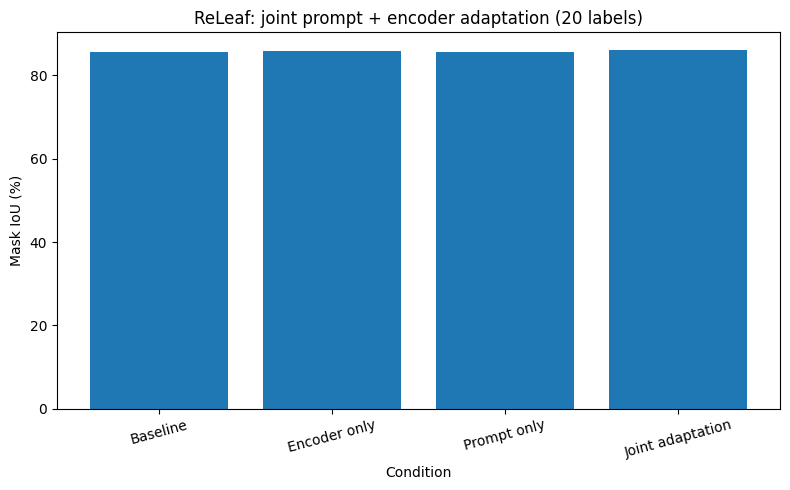

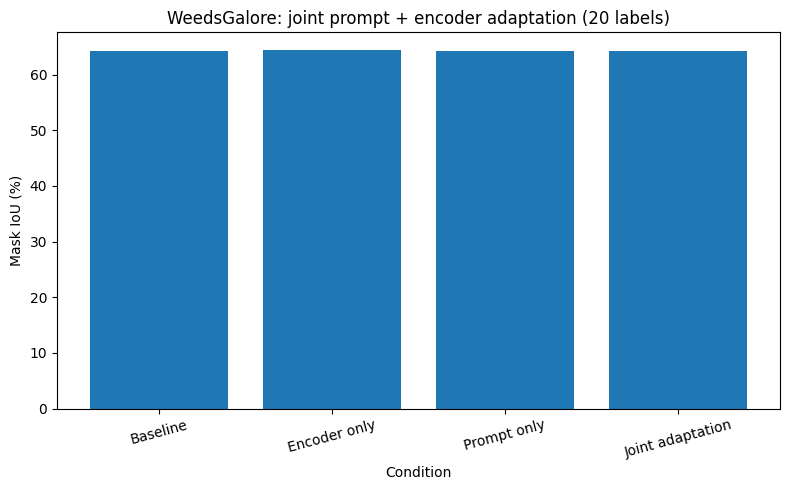

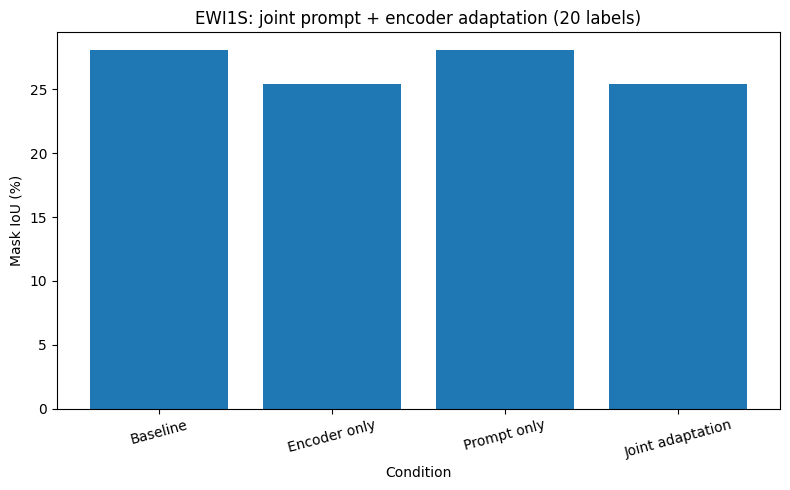

In [47]:
# CELL 28 — Mask-IoU bar charts
for d in TARGET_DATASETS:
    temp=final_summary[final_summary.Dataset==d].copy()
    temp["Condition"]=pd.Categorical(temp.Condition,["Baseline","Encoder only","Prompt only","Joint adaptation"],ordered=True)
    temp=temp.sort_values("Condition")
    plt.figure(figsize=(8,5)); plt.bar(temp.Condition.astype(str),temp["Mask_IoU_%"])
    plt.ylabel("Mask IoU (%)"); plt.xlabel("Condition"); plt.title(f"{d}: joint prompt + encoder adaptation ({LABEL_BUDGET} labels)")
    plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [48]:
# CELL 29 — Box-IoU change caused by AgriCLIP prompt adaptation
rows=[]
for d in TARGET_DATASETS:
    temp=final_summary[final_summary.Dataset==d]
    b=float(temp.loc[temp.Condition=="Baseline","Box_IoU_%"].iloc[0]); a=float(temp.loc[temp.Condition=="Prompt only","Box_IoU_%"].iloc[0])
    rows.append({"Dataset":d,"Original_Box_IoU_%":b,"Adapted_Box_IoU_%":a,"Gain_pp":a-b})
box_comparison=pd.DataFrame(rows); display(box_comparison.round(3))
box_comparison.to_csv(OUTPUT_ROOT/"FINAL_box_prompt_adaptation.csv",index=False)

,Dataset,Original_Box_IoU_%,Adapted_Box_IoU_%,Gain_pp
0,ReLeaf,92.338,92.393,0.055
1,WeedsGalore,95.657,95.942,0.285
2,EWI1S,95.618,95.618,0.000


In [49]:
# CELL 30 —-hypothesis table
rows=[]
for d in TARGET_DATASETS:
    temp=final_summary[final_summary.Dataset==d]
    get=lambda c:float(temp.loc[temp.Condition==c,"Mask_IoU_%"].iloc[0])
    b=get("Baseline"); e=get("Encoder only"); p=get("Prompt only"); j=get("Joint adaptation")
    rows.append({"Dataset":d,"Baseline_IoU_%":b,"Encoder_only_IoU_%":e,"Prompt_only_IoU_%":p,"Joint_IoU_%":j,
                 "Encoder_gain_pp":e-b,"Prompt_gain_pp":p-b,"Joint_gain_pp":j-b,"Joint_vs_best_single_pp":j-max(e,p)})
hypothesis_df=pd.DataFrame(rows); display(hypothesis_df.round(3))
hypothesis_df.to_csv(OUTPUT_ROOT/"FINAL_supervisor_hypothesis_test.csv",index=False)

,Dataset,Baseline_IoU_%,Encoder_only_IoU_%,Prompt_only_IoU_%,Joint_IoU_%,Encoder_gain_pp,Prompt_gain_pp,Joint_gain_pp,Joint_vs_best_single_pp
0,ReLeaf,85.552,85.988,85.636,86.063,0.436,0.084,0.512,0.075
1,WeedsGalore,64.248,64.381,64.206,64.325,0.133,-0.042,0.076,-0.056
2,EWI1S,28.068,25.386,28.068,25.386,-2.682,0.000,-2.682,-2.682


In [50]:
# CELL 31 — Paired per-image Joint vs Baseline + Wilcoxon test
from scipy.stats import wilcoxon
result_objects={"ReLeaf":releaf_result,"WeedsGalore":weedsgalore_result,"EWI1S":ewis1_result}
rows=[]
for d,res in result_objects.items():
    df=res["per_image"]
    b=df[df.condition=="Baseline"][["index","mask_iou"]].rename(columns={"mask_iou":"baseline"})
    j=df[df.condition=="Joint adaptation"][["index","mask_iou"]].rename(columns={"mask_iou":"joint"})
    pair=b.merge(j,on="index"); diff=pair.joint-pair.baseline
    stat,pval=(np.nan,1.0) if np.allclose(diff,0) else wilcoxon(pair.joint,pair.baseline)
    rows.append({"Dataset":d,"Images":len(pair),"Baseline_IoU_%":100*pair.baseline.mean(),"Joint_IoU_%":100*pair.joint.mean(),
                 "Mean_gain_pp":100*diff.mean(),"Median_gain_pp":100*diff.median(),"Joint_better_%":100*(diff>0).mean(),
                 "Joint_worse_%":100*(diff<0).mean(),"Wilcoxon_p":pval})
paired_summary=pd.DataFrame(rows); display(paired_summary.round(4))
paired_summary.to_csv(OUTPUT_ROOT/"FINAL_joint_vs_baseline_paired.csv",index=False)

,Dataset,Images,Baseline_IoU_%,Joint_IoU_%,Mean_gain_pp,Median_gain_pp,Joint_better_%,Joint_worse_%,Wilcoxon_p
0,ReLeaf,34,85.5517,86.0632,0.5115,0.1016,67.6471,32.3529,0.0052
1,WeedsGalore,15,64.2483,64.3248,0.0765,0.1956,53.3333,46.6667,0.6788
2,EWI1S,8,28.0684,25.3861,-2.6824,0.4589,50.0000,37.5000,0.5781


## Optional label-budget ablation
Set `RUN_LABEL_BUDGET_ABLATION = True` in Cell 2 if you also want to test **5, 10, 20, and 50 labels**. The primary final experiment remains the fixed small-label comparison above, so the thesis story stays focused.

In [51]:
# CELL 32 — OPTIONAL 5/10/20/50 label-budget ablation
budget_results=[]
if RUN_LABEL_BUDGET_ABLATION:
    for d in TARGET_DATASETS:
        for budget in LABEL_BUDGETS:
            if budget>len(dataset_splits[d]["train"]): continue
            result=run_joint_adaptation_experiment(d,budget)
            budget_results.append(result["summary"])
    label_budget_summary=pd.concat(budget_results,ignore_index=True)
    label_budget_summary.to_csv(OUTPUT_ROOT/"OPTIONAL_label_budget_ablation.csv",index=False)
    display(label_budget_summary.round(3))
else:
    print("Skipped. Set RUN_LABEL_BUDGET_ABLATION=True to enable.")

Skipped. Set RUN_LABEL_BUDGET_ABLATION=True to enable.


In [52]:
# CELL 33 — Automatic thesis interpretation helper
print("="*80); print("THESIS INTERPRETATION"); print("="*80)
for _,r in hypothesis_df.iterrows():
    print(f"\n{r.Dataset}")
    print(f"  Joint gain over baseline: {r.Joint_gain_pp:+.3f} pp")
    print(f"  Joint vs best single adaptation: {r.Joint_vs_best_single_pp:+.3f} pp")
    if r.Joint_gain_pp>1 and r.Joint_vs_best_single_pp>0:
        print("  -> Strong evidence for an interacting prompt + representation limitation.")
    elif r.Joint_gain_pp>0:
        print("  -> Joint adaptation helps; judge practical significance from gain and paired consistency.")
    else:
        print("  -> Joint adaptation does not improve final masks; supports the characterization-focused conclusion.")
print("\nKey question: does adapting both AgriCLIP prompting and SAM2 representation with small target-domain supervision improve segmentation, especially on EWI1S?")

THESIS INTERPRETATION

ReLeaf
  Joint gain over baseline: +0.512 pp
  Joint vs best single adaptation: +0.075 pp
  -> Joint adaptation helps; judge practical significance from gain and paired consistency.

WeedsGalore
  Joint gain over baseline: +0.076 pp
  Joint vs best single adaptation: -0.056 pp
  -> Joint adaptation helps; judge practical significance from gain and paired consistency.

EWI1S
  Joint gain over baseline: -2.682 pp
  Joint vs best single adaptation: -2.682 pp
  -> Joint adaptation does not improve final masks; supports the characterization-focused conclusion.

Key question: does adapting both AgriCLIP prompting and SAM2 representation with small target-domain supervision improve segmentation, especially on EWI1S?
